In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from utils import calculate_cost_basis_per_time, allocate_weekly_investment, get_decay_rate

In [2]:
# Read AAII.xlsx with header on row 1 (index 1)
aaii_df = pd.read_excel('AAII.xlsx', header=1)
print("AAII columns:", aaii_df.columns.tolist())
print("\nAAII shape:", aaii_df.shape)
print("\nFirst few rows:")
print(aaii_df.head())

AAII columns: ['Company', 'Ticker', 'CurrentPrice($)', '52-Week  High($)', '52-Week  Low($)', 'Market-CapSize($ mil)', 'Price-EarningsRatio(X)', 'Price-to-BookRatio(X)', 'Rel PriceStrgth(%)', 'Notes', 'News']

AAII shape: (29, 11)

First few rows:
                           Company Ticker  CurrentPrice($)  52-Week  High($)  \
0             Alpha Pro Tech, Ltd.    APT             5.55              7.50   
1             Amplify Energy Corp.   AMPY             4.43              6.79   
2             Castor Maritime Inc.   CTRM             1.64              2.66   
3    Columbus McKinnon Corporation   CMCO            14.64             24.40   
4  Core Molding Technologies, Inc.    CMT            22.91             28.69   

   52-Week  Low($)  Market-CapSize($ mil) Price-EarningsRatio(X)  \
0             4.34                   56.6                   14.3   
1             3.65                  183.7                      9   
2             1.57                   15.8                    1.2   

In [3]:
# Read TransactionHistory.xlsx
transactions_df = pd.read_excel('TransactionHistory.xlsx')
print("TransactionHistory columns:", transactions_df.columns.tolist())
print("\nTransactionHistory shape:", transactions_df.shape)
print("\nFirst few rows:")
print(transactions_df.head())

TransactionHistory columns: ['Activity/Trade Date', 'Transaction Date', 'Settlement Date', 'Activity Type', 'Description', 'Symbol', 'Cusip', 'Quantity #', 'Price $', 'Amount $', 'Commission', 'Category', 'Note']

TransactionHistory shape: (2428, 13)

First few rows:
  Activity/Trade Date Transaction Date Settlement Date       Activity Type  \
0          10/13/2026       10/13/2026      10/13/2026            Dividend   
1          10/13/2026       10/13/2026      10/13/2026  Qualified Dividend   
2          10/12/2026       10/12/2026      10/13/2026              Bought   
3          10/12/2026       10/12/2026      10/13/2026              Bought   
4          10/12/2026       10/12/2026      10/13/2026              Bought   

                                         Description Symbol Cusip  Quantity #  \
0        ESCALADE INC DELAWARE DIVIDEND REINVESTMENT   ESCA    --       0.779   
1  ESCALADE INC DELAWARE REC 10/13/26 PAY 10/13/2...   ESCA    --         NaN   
2        GILAT SATEL

In [4]:
# Read deleted_shadow_stocks.txt
with open('deleted_shadow_stocks.txt', 'r') as f:
    deleted_stocks = [line.strip() for line in f if line.strip()]
print("Deleted stocks:", deleted_stocks)

Deleted stocks: ['RYZ', 'ZEUS', 'HOFT', 'LSEA', 'NSYS', 'TITN', 'CLAR', 'KTCC', 'SGMA', 'DCO', 'HURC', 'AP', 'BSET', 'BGFV', 'SCX', 'GORV', 'BZH', 'VSEC', 'STRT', 'VOXX', 'ADES', 'BOOM', 'FONR', 'LAKE', 'SGA', 'VPG']


In [5]:
# Get list of valid tickers from AAII (excluding deleted stocks)
valid_tickers = set(aaii_df['Ticker'].dropna().unique())
valid_tickers = valid_tickers - set(deleted_stocks)
print(f"Number of valid tickers in AAII: {len(valid_tickers)}")
print("Sample valid tickers:", list(valid_tickers)[:10])

Number of valid tickers in AAII: 29
Sample valid tickers: ['NGS', 'ESEA', 'CMCO', 'CTRM', 'OIS', 'RCKY', 'SDHC', 'AMPY', 'CMT', 'RGS']


In [6]:
# Filter transactions to only include stocks in AAII (and not deleted)
filtered_transactions = transactions_df[transactions_df['Symbol'].isin(valid_tickers)].copy()
print(f"Total transactions: {len(transactions_df)}")
print(f"Filtered transactions (only in AAII): {len(filtered_transactions)}")
print("\nSample filtered transactions:")
print(filtered_transactions.head())

Total transactions: 2428
Filtered transactions (only in AAII): 1717

Sample filtered transactions:
  Activity/Trade Date Transaction Date Settlement Date       Activity Type  \
0          10/13/2026       10/13/2026      10/13/2026            Dividend   
1          10/13/2026       10/13/2026      10/13/2026  Qualified Dividend   
2          10/12/2026       10/12/2026      10/13/2026              Bought   
3          10/12/2026       10/12/2026      10/13/2026              Bought   
4          10/12/2026       10/12/2026      10/13/2026              Bought   

                                         Description Symbol Cusip  Quantity #  \
0        ESCALADE INC DELAWARE DIVIDEND REINVESTMENT   ESCA    --       0.779   
1  ESCALADE INC DELAWARE REC 10/13/26 PAY 10/13/2...   ESCA    --         NaN   
2        GILAT SATELLITE NTWKS LTD UNSOLICITED TRADE   GILT    --       2.000   
3                   SMART SAND INC UNSOLICITED TRADE    SND    --      12.000   
4              CASTOR MARIT

In [7]:
# Convert date columns to datetime with mixed format handling
filtered_transactions['Activity/Trade Date'] = pd.to_datetime(filtered_transactions['Activity/Trade Date'], format='mixed')
filtered_transactions['Transaction Date'] = pd.to_datetime(filtered_transactions['Transaction Date'], format='mixed')
filtered_transactions['Settlement Date'] = pd.to_datetime(filtered_transactions['Settlement Date'], format='mixed')

# Parse activity type to identify buys and sells
print("Activity Type values:")
print(filtered_transactions['Activity Type'].value_counts())

Activity Type values:
Activity Type
Bought                977
0                     474
Dividend               87
Qualified Dividend     66
Stock Split             1
Name: count, dtype: int64


In [8]:
decay_rate = get_decay_rate(90, 180, 0.5)  # Example: 50% decay over 90 to 180 days
reference_date = pd.Timestamp.now() + pd.Timedelta(days=7)  # 7 days from present
cost_basis_df = calculate_cost_basis_per_time(filtered_transactions, decay_rate=decay_rate, reference_date=reference_date)
print("Cost basis per time:")
print(cost_basis_df)

# Allocate weekly investment
weekly_new_amount = 350
allocation_df, updated_cost_basis_df = allocate_weekly_investment(cost_basis_df, aaii_df, weekly_new_amount, filtered_transactions, decay_rate=decay_rate, reference_date=reference_date)
print(f"\nWeekly investment allocation (${weekly_new_amount}) as of {reference_date.date()}:")
print(allocation_df)

TypeError: calculate_cost_basis_per_time() got an unexpected keyword argument 'reference_date'

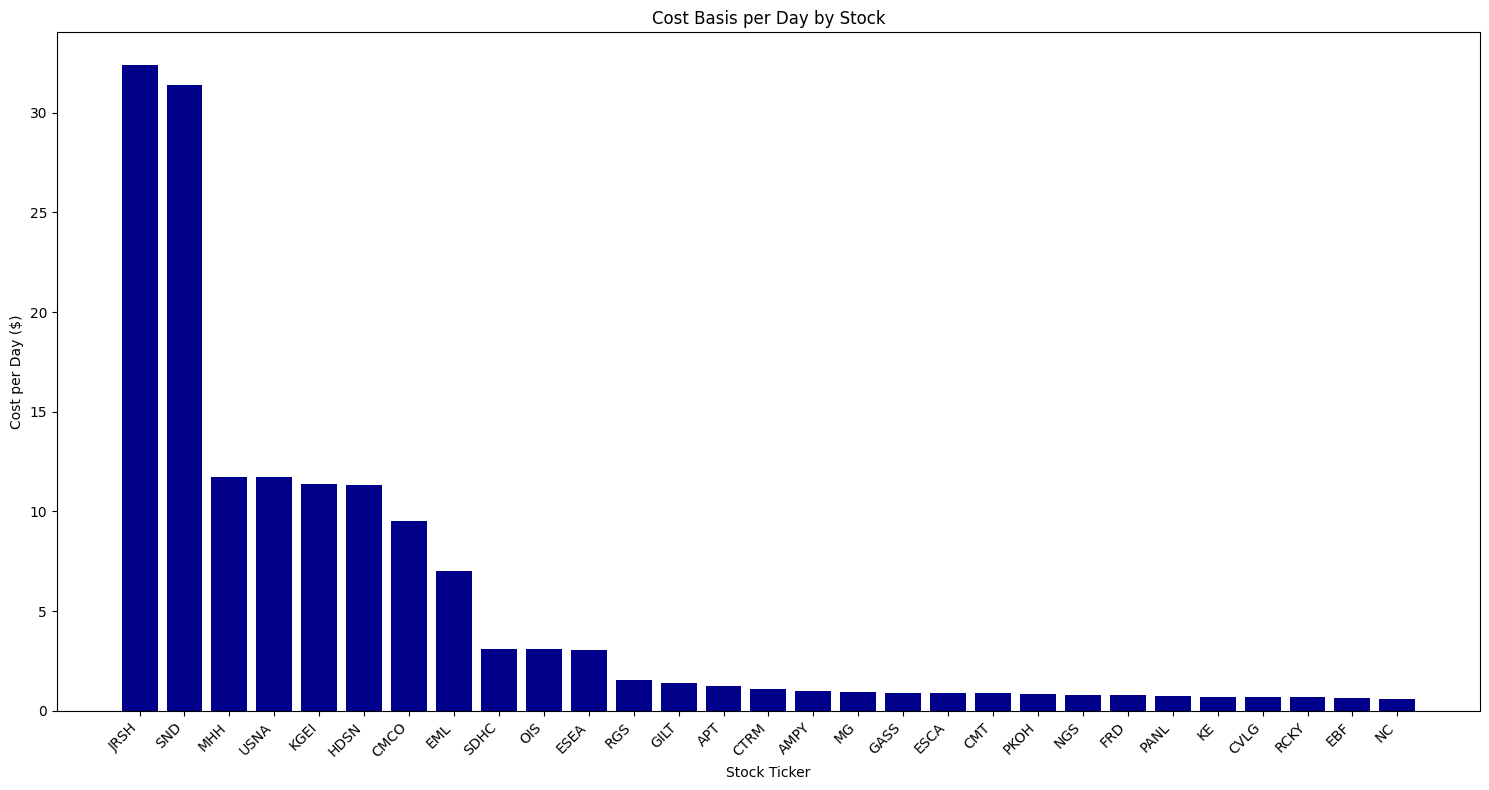

In [ ]:
# Plot bar chart per stock showing cost basis per unit time
plt.figure(figsize=(15, 8))

# Sort by cost per day descending
plot_df = cost_basis_df.sort_values('Cost per Day', ascending=False)

plt.bar(plot_df['Ticker'], plot_df['Cost per Day'], color='darkblue')
plt.ylabel('Cost per Day ($)')
plt.xlabel('Stock Ticker')
plt.title('Cost Basis per Day by Stock')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

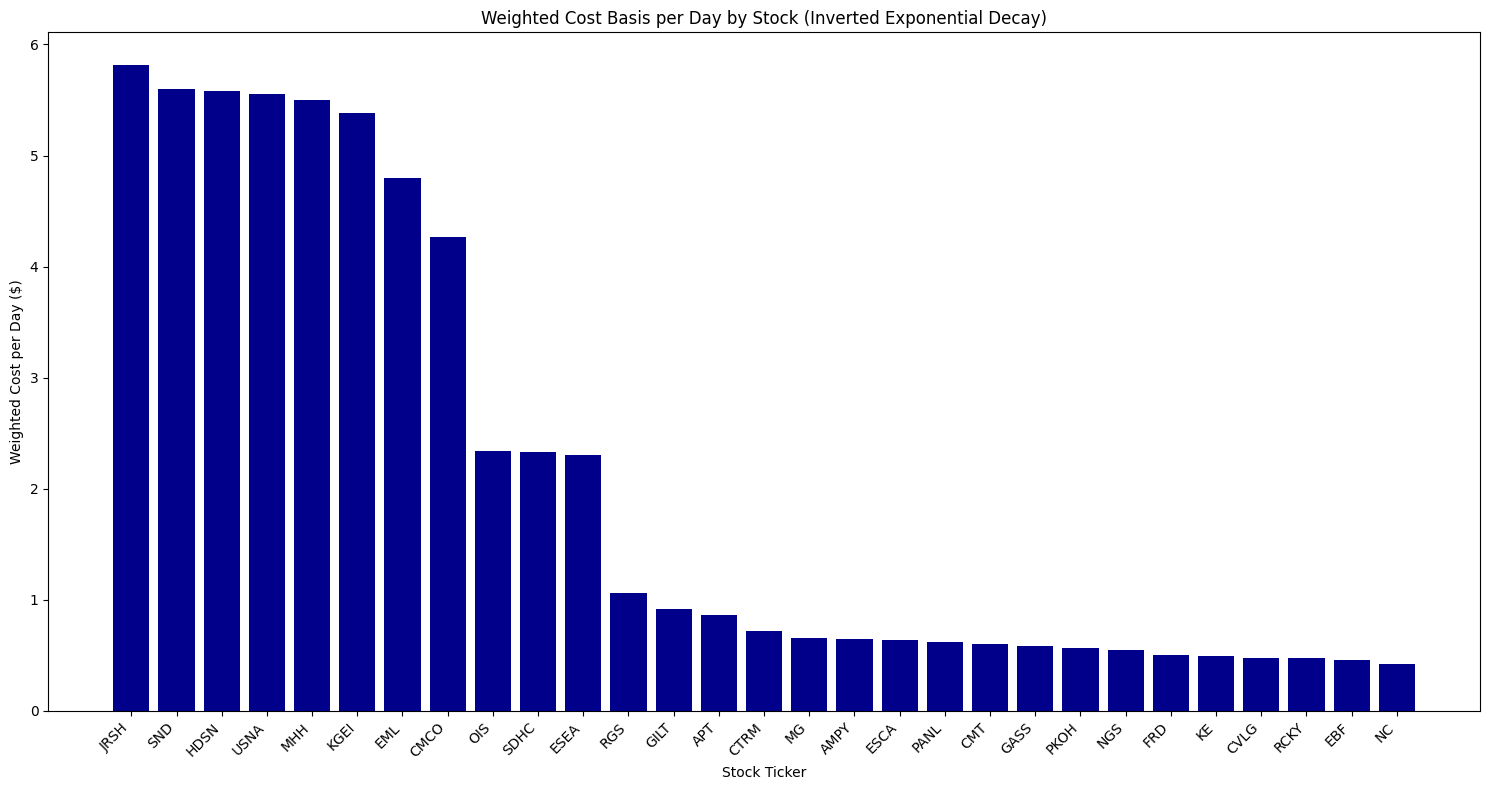

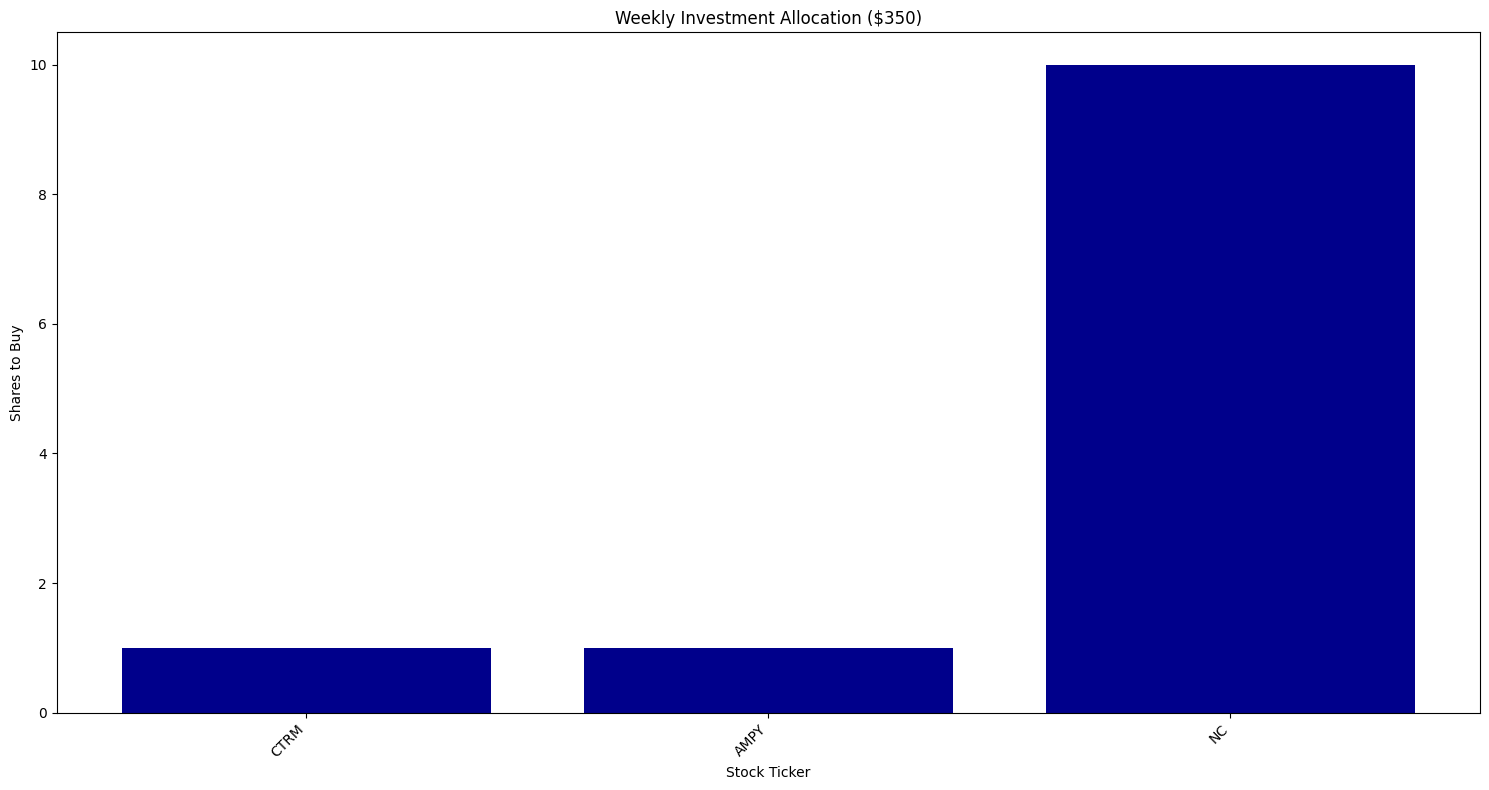

Updated cost basis after purchases:
   Ticker  Weighted Cost per Day  Net Cost  Total Shares
0    ESCA               0.633666   1092.60        69.000
1    GILT               0.918557   1047.50        85.000
2     SND               5.602339    815.69       154.000
3    CTRM               0.730119    946.01       448.000
4     EML               4.796587   1473.91        67.000
5    KGEI               5.385890   1354.85       252.000
6    RCKY               0.471456   1035.10        32.000
7     FRD               0.506065    959.51        39.000
8    CMCO               4.268024   1120.55        71.000
9    PANL               0.619948   1459.72       279.000
10   JRSH               5.818007    842.51       153.000
11   HDSN               5.584063   1347.92       236.000
12    OIS               2.340961   1490.80       208.000
13   ESEA               2.307579   1482.71        25.000
14   GASS               0.584426    923.57       115.000
15   AMPY               0.652966    942.28       220

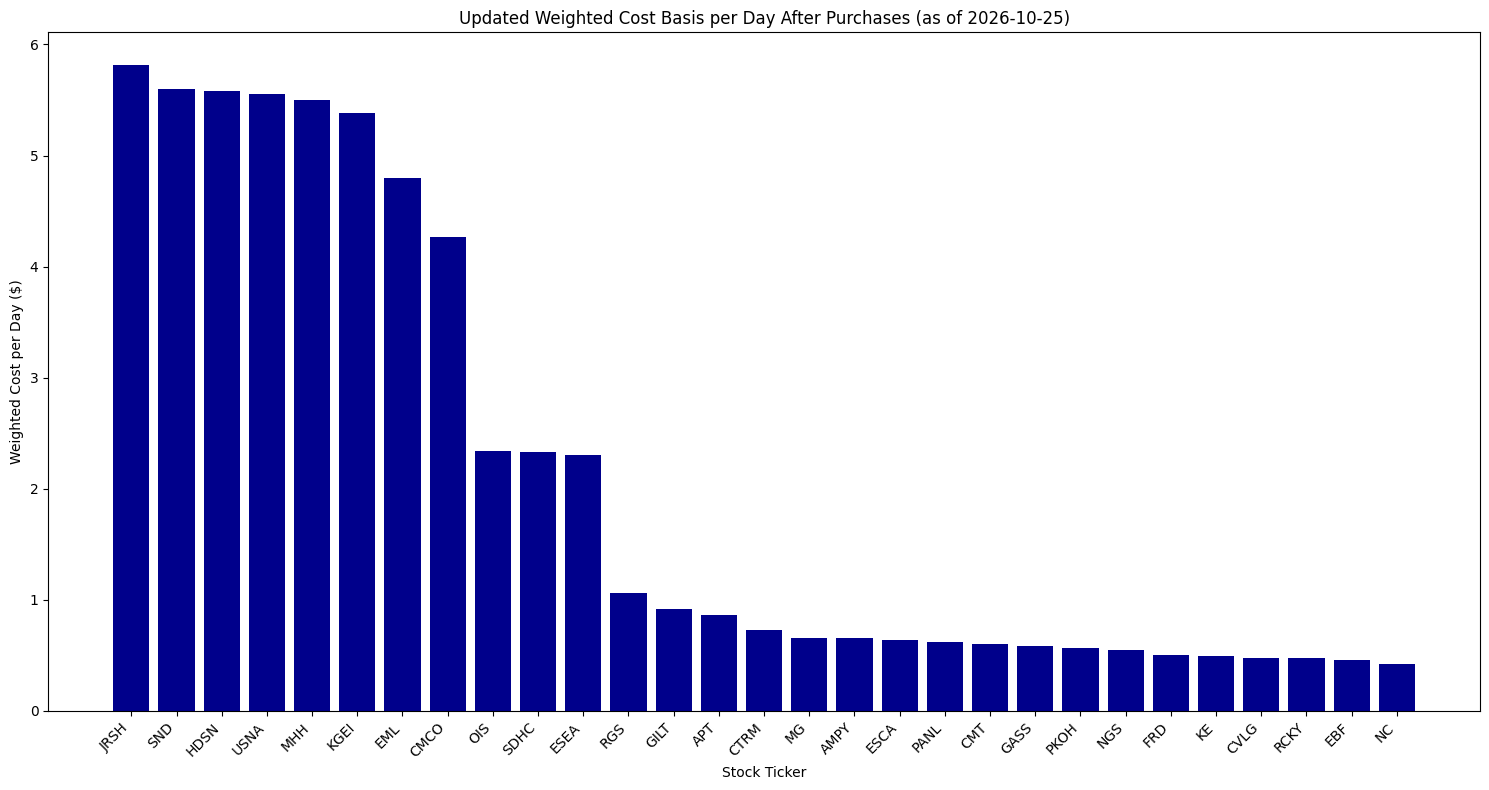

In [ ]:
# Plot weighted cost per day (with inverted exponential decay)
plt.figure(figsize=(15, 8))

plot_df3 = cost_basis_df.sort_values('Weighted Cost per Day', ascending=False)

plt.bar(plot_df3['Ticker'], plot_df3['Weighted Cost per Day'], color='darkblue')
plt.ylabel('Weighted Cost per Day ($)')
plt.xlabel('Stock Ticker')
plt.title('Weighted Cost Basis per Day by Stock (Inverted Exponential Decay)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Plot weekly investment allocation
plt.figure(figsize=(15, 8))

if len(allocation_df) > 0:
    plt.bar(allocation_df['Ticker'], allocation_df['Shares to Buy'], color='darkblue')
    plt.ylabel('Shares to Buy')
    plt.xlabel('Stock Ticker')
    plt.title(f'Weekly Investment Allocation (${weekly_new_amount})')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No allocation - unable to buy any shares with the given amount")

# Debug: Print updated cost basis before plotting
print("Updated cost basis after purchases:")
print(updated_cost_basis_df[['Ticker', 'Weighted Cost per Day', 'Net Cost', 'Total Shares']])

# Plot updated weighted cost per day after purchases
if len(updated_cost_basis_df) > 0:
    plot_df4 = updated_cost_basis_df.sort_values('Weighted Cost per Day', ascending=False)
    print(f"Plotting updated weighted cost, min: {plot_df4['Weighted Cost per Day'].min()}, max: {plot_df4['Weighted Cost per Day'].max()}")
    
    # Check if all values are zero or very small
    if plot_df4['Weighted Cost per Day'].max() < 0.01:
        print("Warning: All weighted cost values are very small (near zero)")
        print("This is expected because new purchases at reference_date have weight = 0 in inverted decay formula")
        print("Let's plot Net Cost instead to see the actual values:")
        
        plt.figure(figsize=(15, 8))
        plot_df5 = updated_cost_basis_df.sort_values('Net Cost', ascending=False)
        plt.bar(plot_df5['Ticker'], plot_df5['Net Cost'], color='darkblue')
        plt.ylabel('Net Cost ($)')
        plt.xlabel('Stock Ticker')
        plt.title(f'Net Cost After Purchases (as of {reference_date.date()})')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
    else:
        plt.figure(figsize=(15, 8))
        plt.bar(plot_df4['Ticker'], plot_df4['Weighted Cost per Day'], color='darkblue')
        plt.ylabel('Weighted Cost per Day ($)')
        plt.xlabel('Stock Ticker')
        plt.title(f'Updated Weighted Cost Basis per Day After Purchases (as of {reference_date.date()})')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
else:
    print("No updated cost basis data to plot")